In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

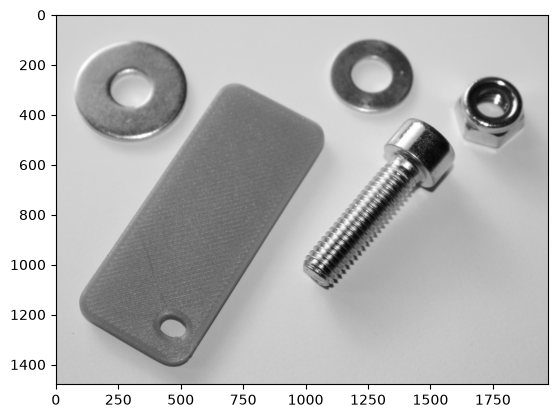

In [2]:
image = cv2.imread("image.jpg")
grayscale = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
plt.imshow(grayscale, 'gray')

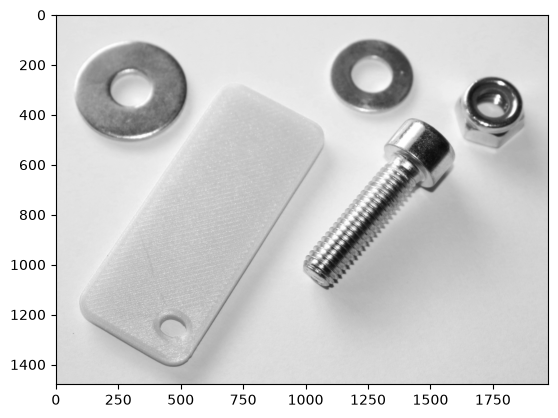

In [3]:
b, g, r = cv2.split(image)
plt.imshow(cv2.cvtColor(b, cv2.COLOR_BGR2RGB))

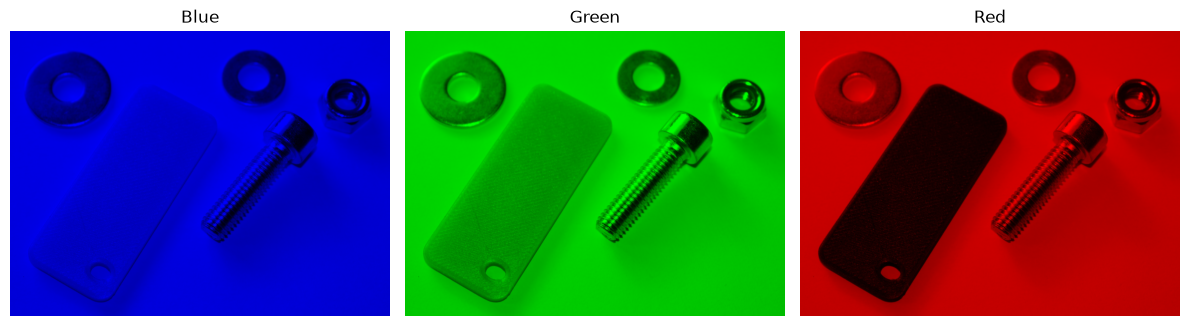

In [4]:
zeros = np.zeros_like(g)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
titles = ['Blue', 'Green', 'Red']
images = [ cv2.merge([b, zeros, zeros]), cv2.merge([zeros, g, zeros]), cv2.merge([zeros, zeros, r])]

for ax, img, title in zip(axes, images, titles):
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis('off')

plt.tight_layout()
plt.show()

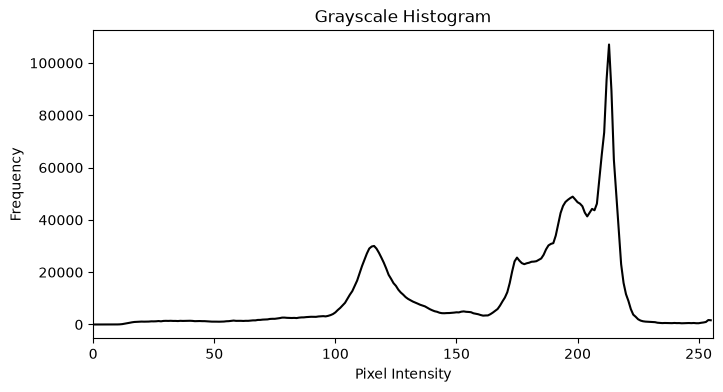

In [5]:
hist = cv2.calcHist([grayscale], [0], None, [256], [0, 256])

plt.figure(figsize=(8, 4))
plt.plot(hist, color='black')
plt.title('Grayscale Histogram')
plt.xlabel('Pixel Intensity')
plt.ylabel('Frequency')
plt.xlim([0, 256])
plt.show()

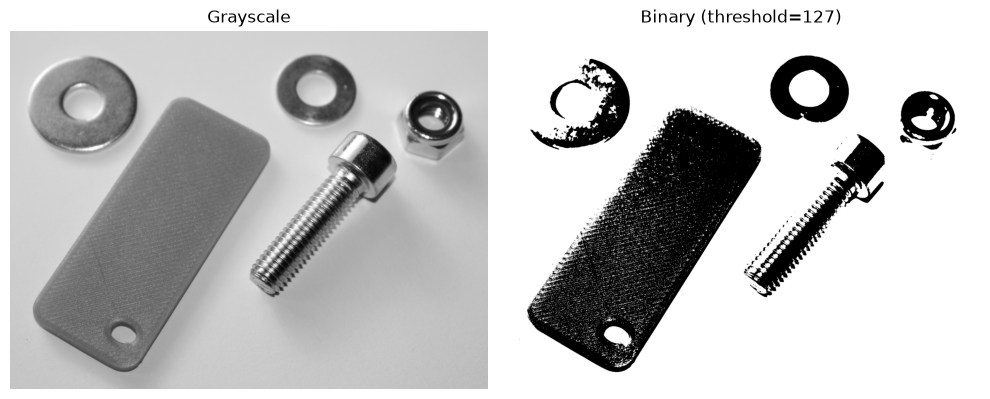

In [6]:
_, binary = cv2.threshold(
    grayscale,
    127,
    255,
    cv2.THRESH_BINARY
)


fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(grayscale, cmap='gray')
axes[0].set_title('Grayscale')
axes[0].axis('off')
b
axes[1].imshow(binary, cmap='gray')
axes[1].set_title('Binary (threshold=127)')
axes[1].axis('off')

plt.tight_layout()
plt.show()

155.0


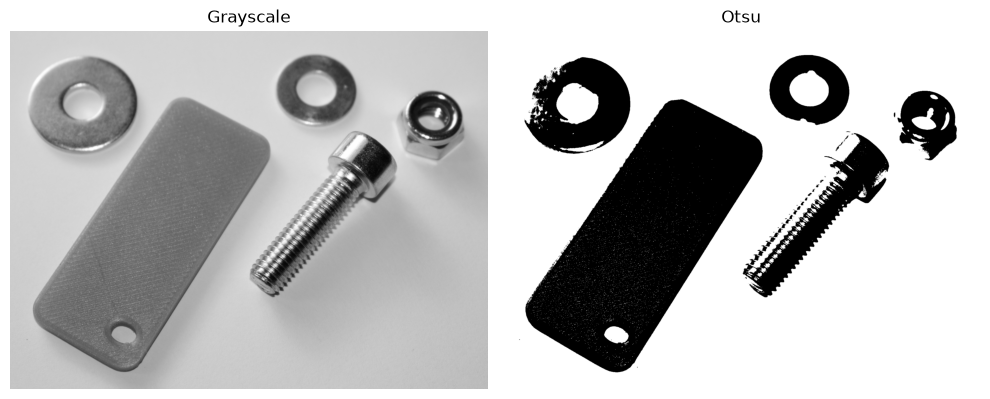

In [7]:
t, otsu = cv2.threshold(
    grayscale,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

print(t)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(grayscale, cmap='gray')
axes[0].set_title('Grayscale')
axes[0].axis('off')

axes[1].imshow(otsu, cmap='gray')
axes[1].set_title('Otsu')
axes[1].axis('off')

plt.tight_layout()
plt.show()

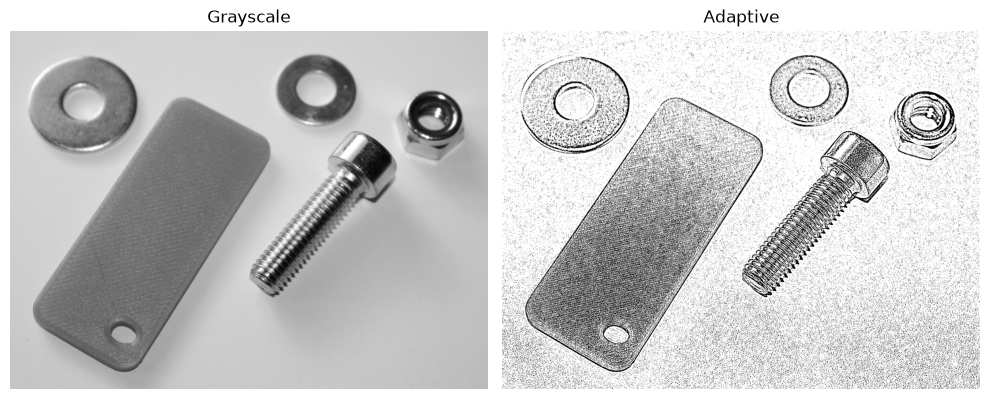

In [8]:
adaptive = cv2.adaptiveThreshold(
    grayscale,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    11,
    2
)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(grayscale, cmap='gray')
axes[0].set_title('Grayscale')
axes[0].axis('off')

axes[1].imshow(adaptive, cmap='gray')
axes[1].set_title('Adaptive')
axes[1].axis('off')

plt.tight_layout()
plt.show()

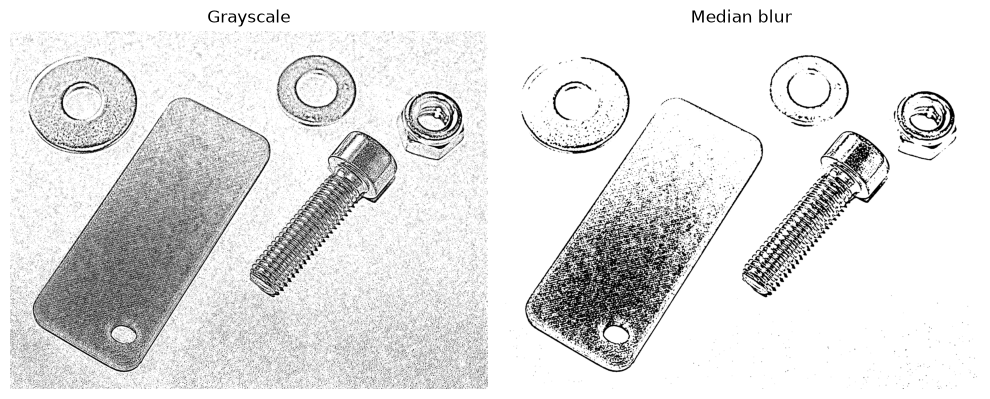

In [9]:
median = cv2.medianBlur(
    adaptive,
    5
)


fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(adaptive, cmap='gray')
axes[0].set_title('Grayscale')
axes[0].axis('off')

axes[1].imshow(median, cmap='gray')
axes[1].set_title('Median blur')
axes[1].axis('off')

plt.tight_layout()
plt.show()

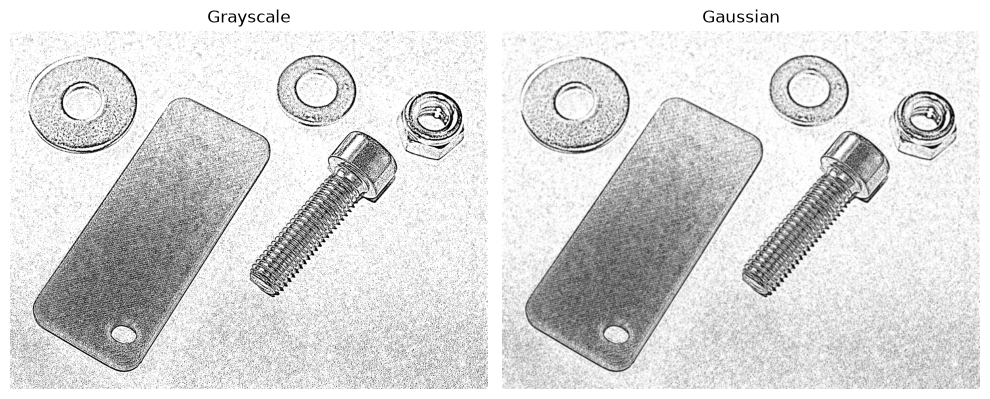

In [10]:
blur = cv2.GaussianBlur(
   adaptive,
   (9, 9),
   0
)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(adaptive, cmap='gray')
axes[0].set_title('Grayscale')
axes[0].axis('off')

axes[1].imshow(blur, cmap='gray')
axes[1].set_title('Gaussian')
axes[1].axis('off')

plt.tight_layout()
plt.show()

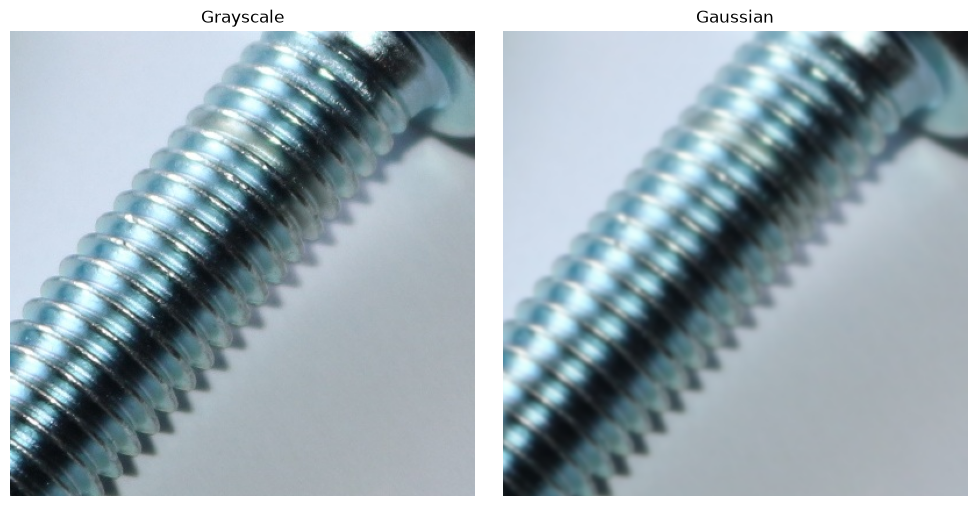

In [11]:
img_blur = cv2.GaussianBlur(
   image,
   (9, 9),
   0
)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(cv2.cvtColor(image[600:1000,1100:1500], cv2.COLOR_BGR2RGB))
axes[0].set_title('Grayscale')
axes[0].axis('off')

axes[1].imshow(cv2.cvtColor(img_blur[600:1000,1100:1500], cv2.COLOR_BGR2RGB))
axes[1].set_title('Gaussian')
axes[1].axis('off')

plt.tight_layout()
plt.show()

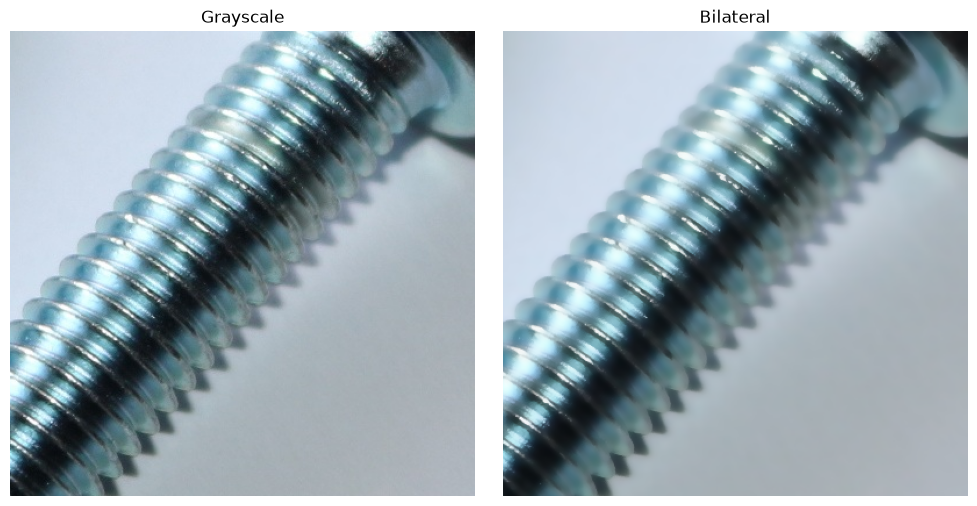

In [12]:
bilateral = cv2.bilateralFilter(
    image,
    9,
    75,
    75
)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(cv2.cvtColor(image[600:1000,1100:1500], cv2.COLOR_BGR2RGB))
axes[0].set_title('Grayscale')
axes[0].axis('off')

axes[1].imshow(cv2.cvtColor(bilateral[600:1000,1100:1500], cv2.COLOR_BGR2RGB))
axes[1].set_title('Bilateral')
axes[1].axis('off')

plt.tight_layout()
plt.show()

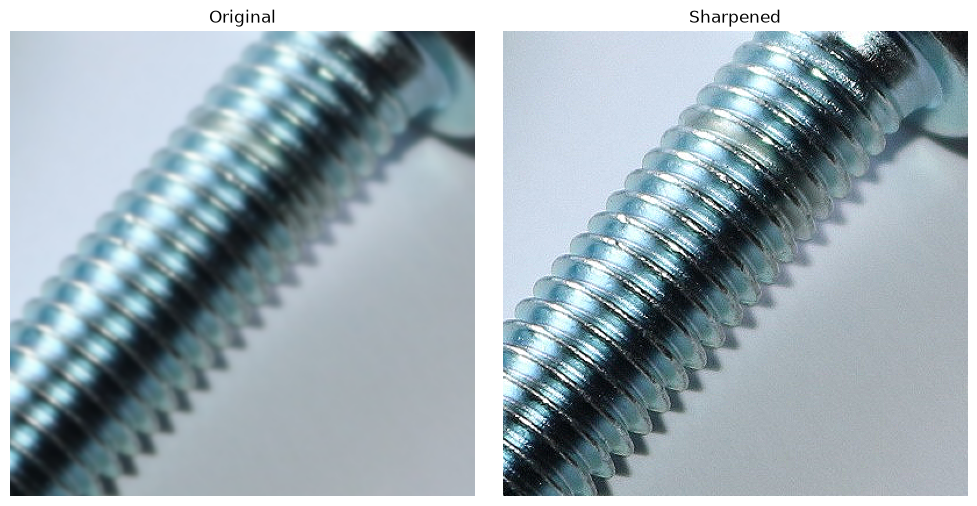

In [13]:
kernel = np.array([[ 0, -1,  0],
                    [-1,  5, -1],
                    [ 0, -1,  0]])
sharpened = cv2.filter2D(image, -1, kernel)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(cv2.cvtColor(img_blur[600:1000,1100:1500], cv2.COLOR_BGR2RGB))
axes[0].set_title('Original')
axes[0].axis('off')
axes[1].imshow(cv2.cvtColor(sharpened[600:1000,1100:1500], cv2.COLOR_BGR2RGB))
axes[1].set_title('Sharpened')
axes[1].axis('off')
plt.tight_layout()
plt.show()

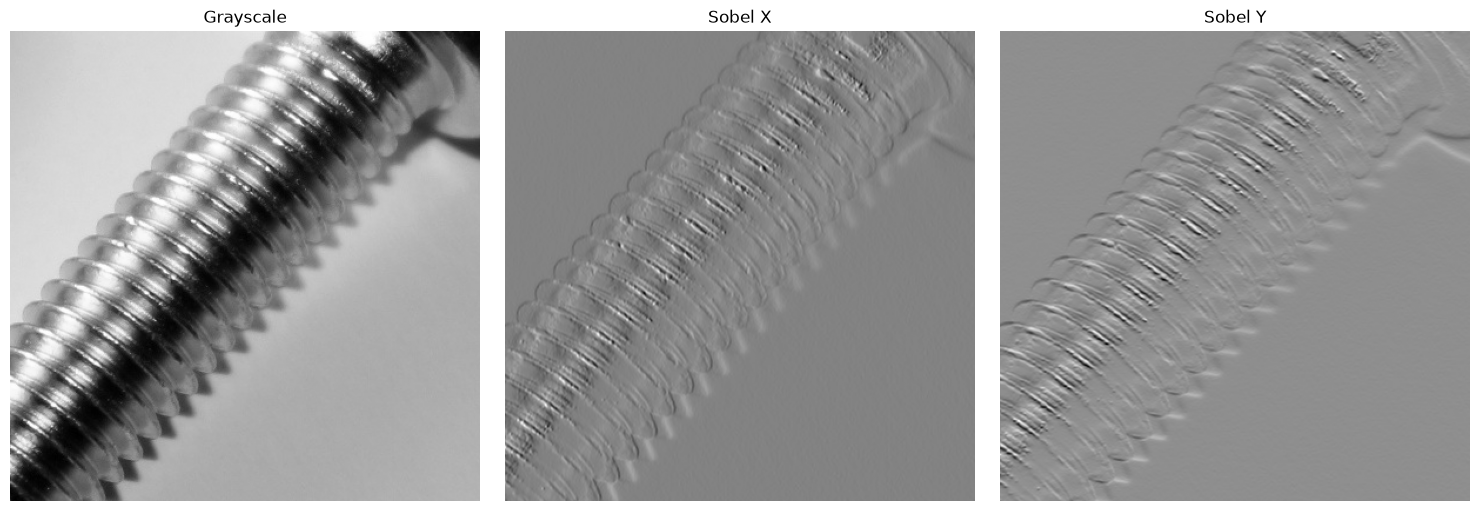

In [14]:
sobel_x = cv2.Sobel(
    grayscale,
    cv2.CV_64F,
    1,
    0,
    ksize=3
)

sobel_y = cv2.Sobel(
    grayscale,
    cv2.CV_64F,
    0,
    1,
    ksize=3
)


fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(grayscale[600:1000,1100:1500], cmap='gray')
axes[0].set_title('Grayscale')
axes[0].axis('off')

axes[1].imshow(sobel_x[600:1000,1100:1500], cmap='gray')
axes[1].set_title('Sobel X')
axes[1].axis('off')

axes[2].imshow(sobel_y[600:1000,1100:1500], cmap='gray')
axes[2].set_title('Sobel Y')
axes[2].axis('off')

plt.tight_layout()
plt.show()

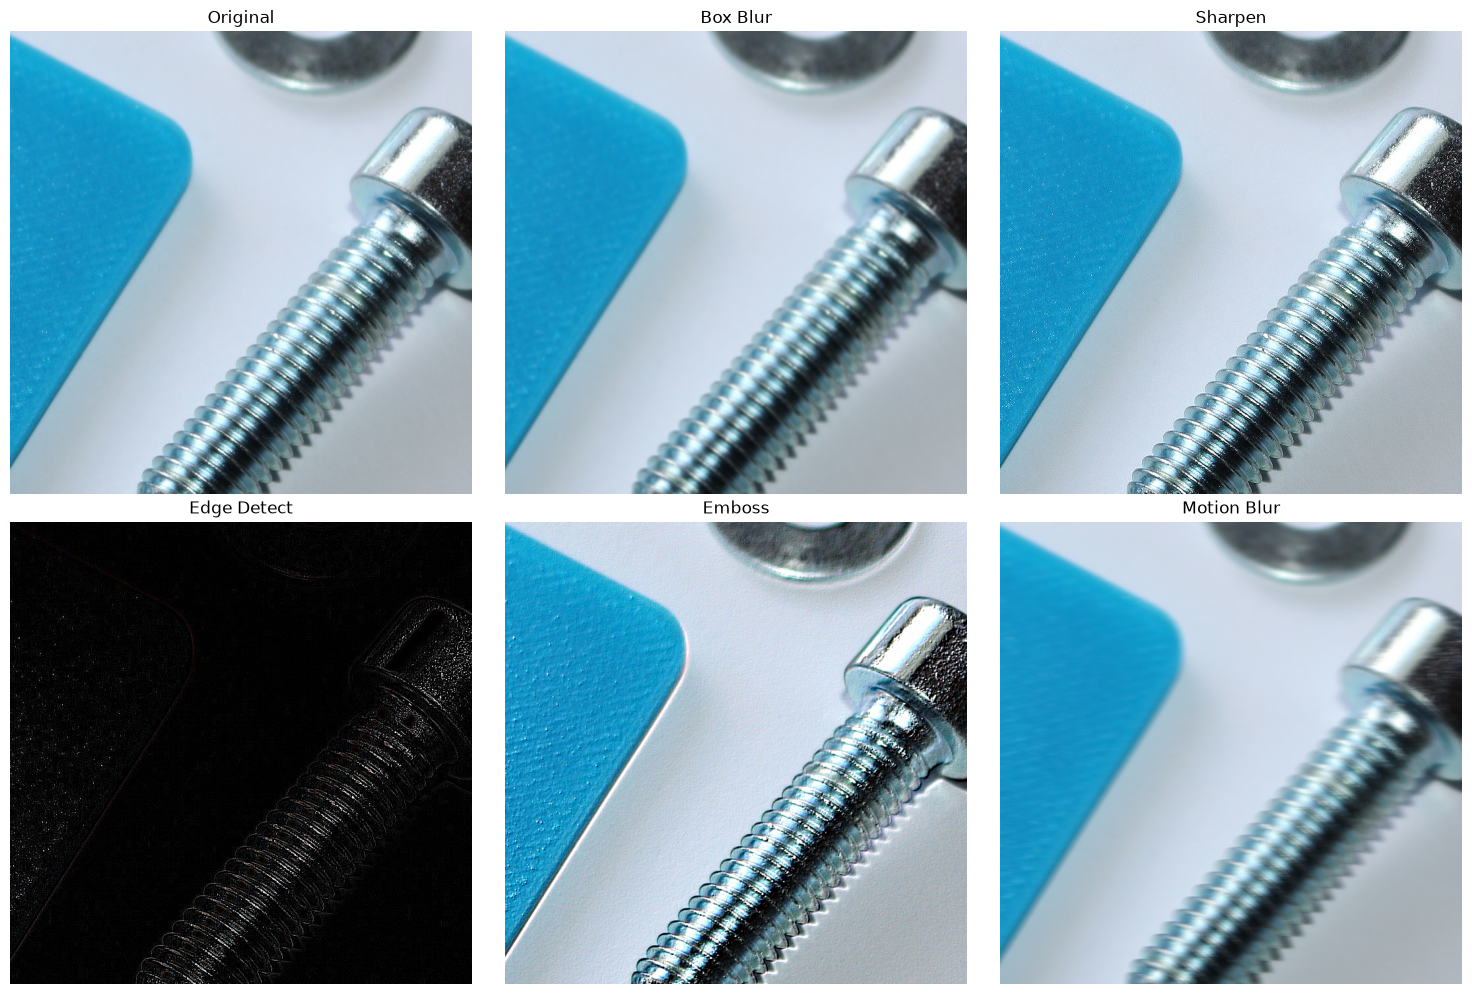

In [15]:
# --- Box blur (averaging) ---
box_kernel = np.ones((5, 5), np.float32) / 25
box_blur = cv2.filter2D(image, -1, box_kernel)
 
# --- Sharpen ---
sharpen_kernel = np.array([[ 0, -1,  0],
                            [-1,  5, -1],
                            [ 0, -1,  0]])
sharpened = cv2.filter2D(image, -1, sharpen_kernel)
 
# --- Edge detection ---
edge_kernel = np.array([[-1, -1, -1],
                         [-1,  8, -1],
                         [-1, -1, -1]])
edges = cv2.filter2D(image, -1, edge_kernel)
 
# --- Emboss ---
emboss_kernel = np.array([[-2, -1, 0],
                           [-1,  1, 1],
                           [ 0,  1, 2]])
embossed = cv2.filter2D(image, -1, emboss_kernel)
 
# --- Motion blur (diagonal) ---
size = 15
motion_kernel = np.zeros((size, size))
motion_kernel[int((size - 1) / 2), :] = np.ones(size)
motion_kernel = motion_kernel / size
motion_blur = cv2.filter2D(image, -1, motion_kernel)
 
# --- Outline / Laplacian-like ---
outline_kernel = np.array([[-1, -1, -1],
                            [-1,  9, -1],
                            [-1, -1, -1]])
outline = cv2.filter2D(image, -1, outline_kernel)
 
# --- Display all together ---
results = [
    ('Original', image[300:1000,800:1500]),
    ('Box Blur', box_blur[300:1000,800:1500]),
    ('Sharpen', sharpened[300:1000,800:1500]),
    ('Edge Detect', edges[300:1000,800:1500]),
    ('Emboss', embossed[300:1000,800:1500]),
    ('Motion Blur', motion_blur[300:1000,800:1500]),
]
 
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.ravel()
 
for ax, (title, img) in zip(axes, results):
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis('off')
 
plt.tight_layout()
plt.show()

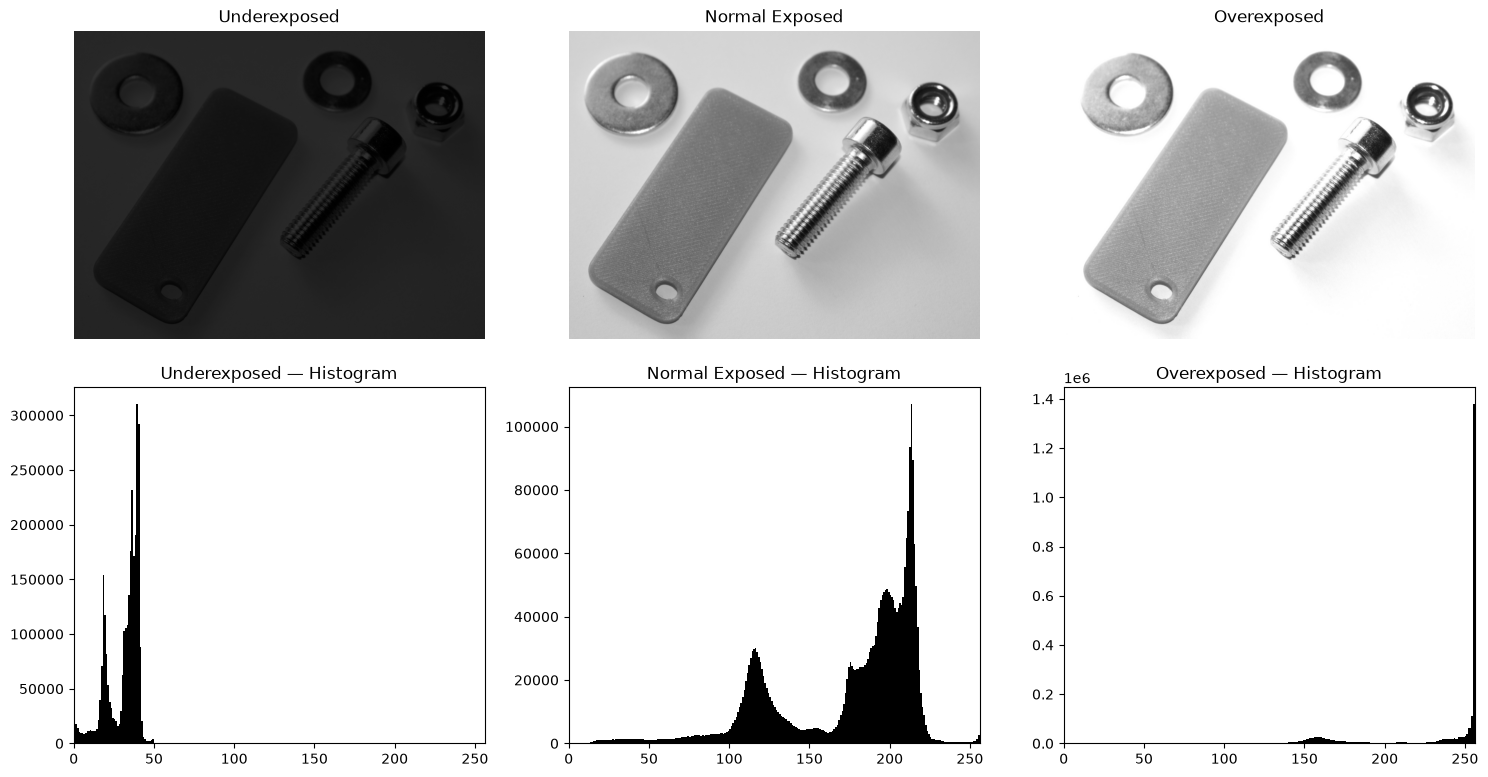

In [16]:
underexposed_img = cv2.imread('under_exposed_image.jpg', cv2.IMREAD_GRAYSCALE)
normal_img = cv2.imread('image.jpg', cv2.IMREAD_GRAYSCALE)
overexposed_img = cv2.imread('over_exposed_image.jpg', cv2.IMREAD_GRAYSCALE)

# --- Display images ---
images = [
    ('Underexposed', underexposed_img),
    ('Normal Exposed', normal_img),
    ('Overexposed', overexposed_img),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for i, (title, img) in enumerate(images):
    # Top row: Display images
    axes[0, i].imshow(img, cmap='gray', vmin=0, vmax=255)
    axes[0, i].set_title(title)
    axes[0, i].axis('off')

    # Bottom row: Plot corresponding histograms
    axes[1, i].hist(img.ravel(), bins=256, range=[0, 256], color='black')
    axes[1, i].set_title(f'{title} — Histogram')
    axes[1, i].set_xlim([0, 256])

plt.tight_layout()
plt.show()

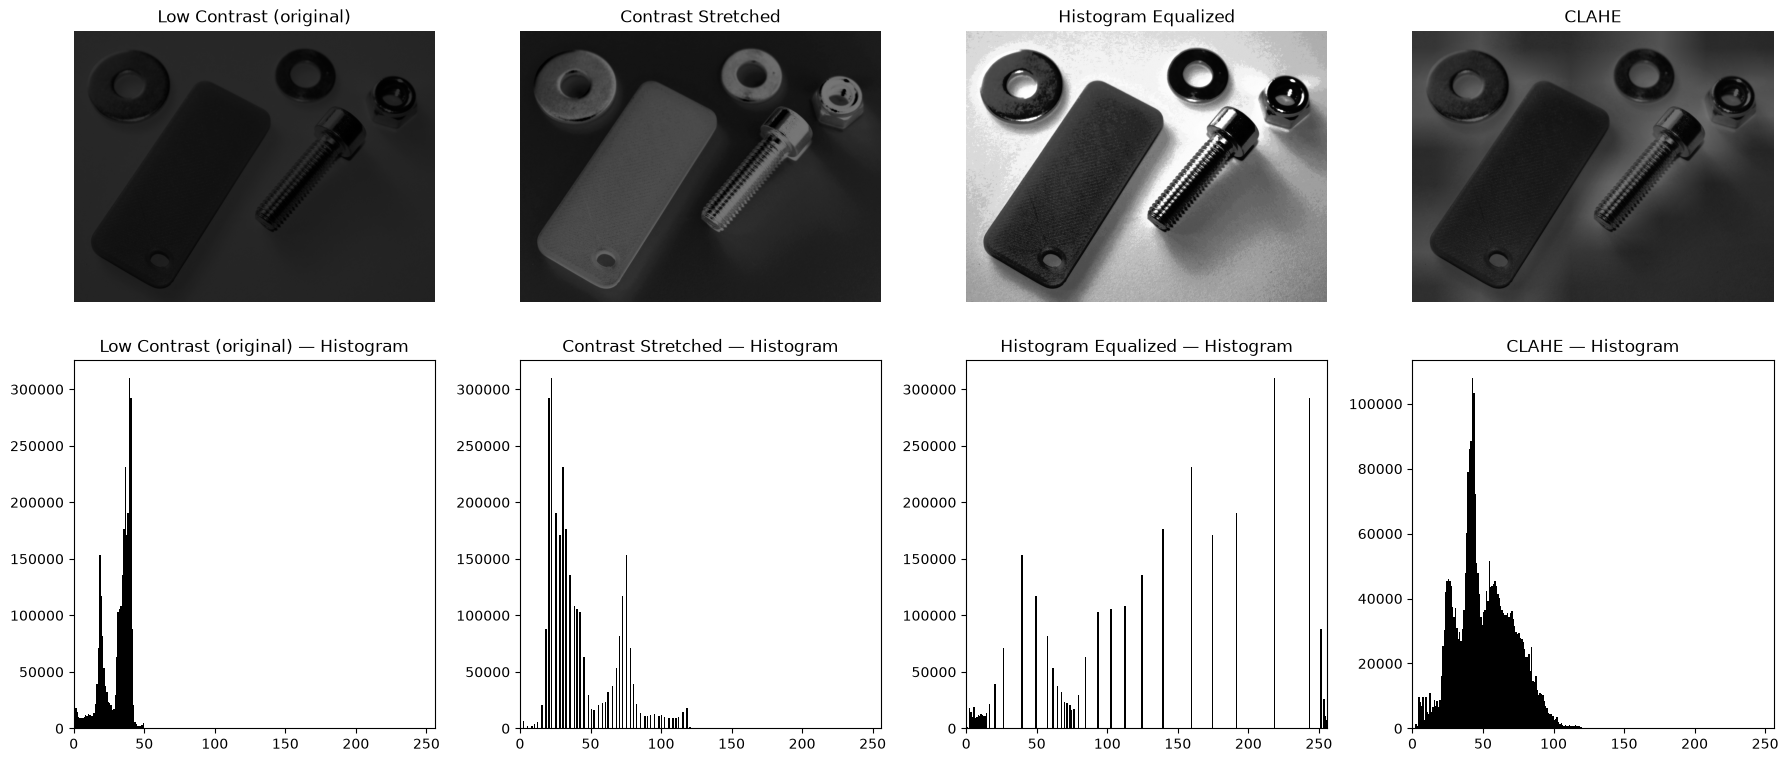

In [17]:
low_contrast = cv2.imread('under_exposed_image.jpg', cv2.IMREAD_GRAYSCALE)

# --- Method 1: Manual contrast/brightness adjustment ---
# new_pixel = alpha * pixel + beta  (alpha > 1 increases contrast)
alpha = 2.5   # contrast control
beta = -120   # brightness control (recenter after stretching)
contrast_adjusted = cv2.convertScaleAbs(low_contrast, alpha=alpha, beta=beta)
 
# --- Method 2: Histogram equalization ---
equalized = cv2.equalizeHist(low_contrast)
 
# --- Method 3: CLAHE (adaptive, avoids over-amplifying noise) ---
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
clahe_result = clahe.apply(low_contrast)
 
# --- Display images ---
images = [
    ('Low Contrast (original)', low_contrast),
    ('Contrast Stretched', contrast_adjusted),
    ('Histogram Equalized', equalized),
    ('CLAHE', clahe_result),
]
 
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
 
for i, (title, img) in enumerate(images):
    axes[0, i].imshow(img, cmap='gray', vmin=0, vmax=255)
    axes[0, i].set_title(title)
    axes[0, i].axis('off')
 
    axes[1, i].hist(img.ravel(), bins=256, range=[0, 256], color='black')
    axes[1, i].set_title(f'{title} — Histogram')
    axes[1, i].set_xlim([0, 256])
 
plt.tight_layout()
plt.show()
 

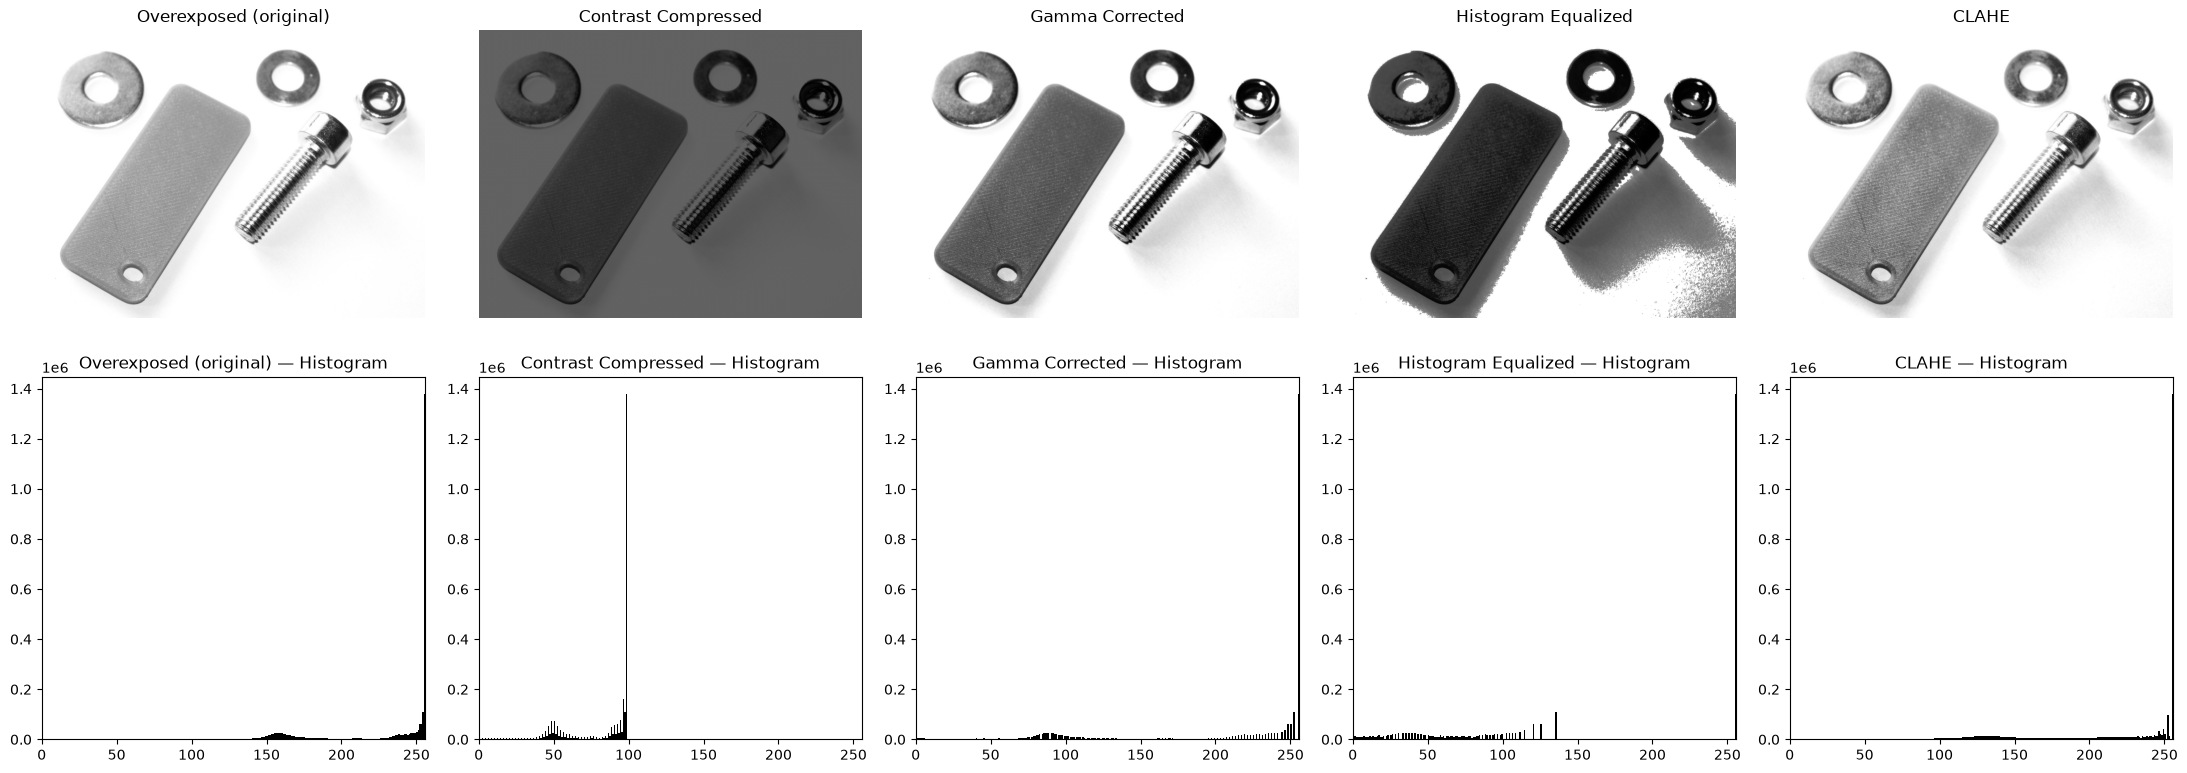

In [18]:
over_exposed = cv2.imread('over_exposed_image.jpg', cv2.IMREAD_GRAYSCALE)

# --- Method 1: Manual contrast/brightness — compress DOWN, not up ---
# alpha < 1 shrinks the range, negative beta shifts everything darker
alpha = 0.5
beta = -30
contrast_adjusted = cv2.convertScaleAbs(over_exposed, alpha=alpha, beta=beta)

# --- Method 2: Gamma correction (better for highlight recovery) ---
# gamma > 1 compresses highlights while preserving shadow/midtone detail
gamma = 2.2
lut = np.array([((i / 255.0) ** gamma) * 255 for i in range(256)], dtype=np.uint8)
gamma_corrected = cv2.LUT(over_exposed, lut)

# --- Method 3: Histogram equalization ---
# Note: won't fix the 255 spike itself (clipped pixels stay mapped to 255),
# but redistributes everything below it more evenly
equalized = cv2.equalizeHist(over_exposed)

# --- Method 4: CLAHE — best general option for real overexposed photos ---
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
clahe_result = clahe.apply(over_exposed)

images = [
    ('Overexposed (original)', over_exposed),
    ('Contrast Compressed', contrast_adjusted),
    ('Gamma Corrected', gamma_corrected),
    ('Histogram Equalized', equalized),
    ('CLAHE', clahe_result),
]

fig, axes = plt.subplots(2, 5, figsize=(22, 8))

for i, (title, img) in enumerate(images):
    axes[0, i].imshow(img, cmap='gray', vmin=0, vmax=255)
    axes[0, i].set_title(title)
    axes[0, i].axis('off')

    axes[1, i].hist(img.ravel(), bins=256, range=[0, 256], color='black')
    axes[1, i].set_title(f'{title} — Histogram')
    axes[1, i].set_xlim([0, 256])

plt.tight_layout()
plt.show()

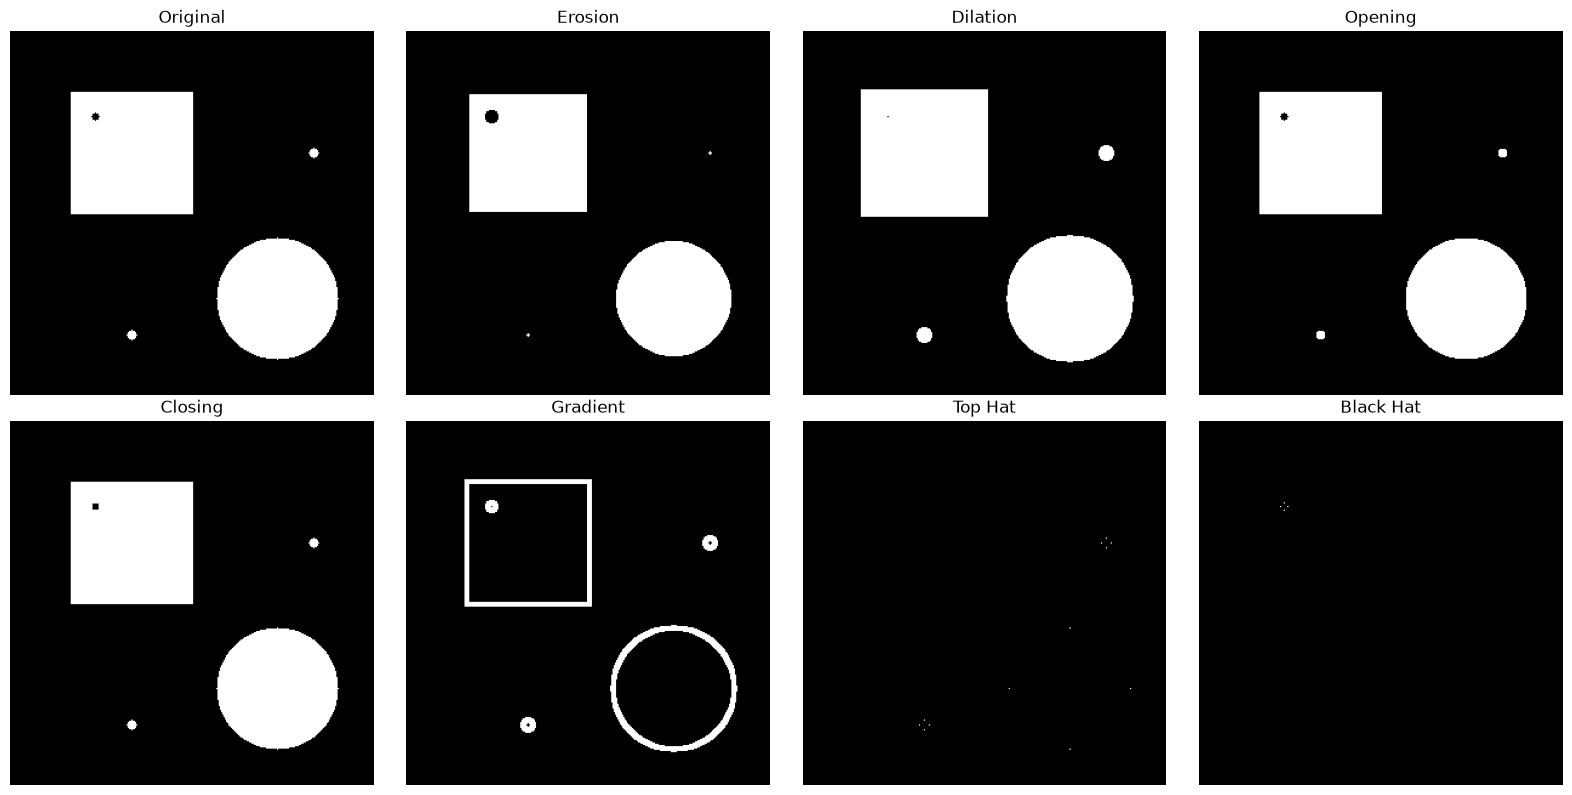

In [19]:
# --- Generate a synthetic binary image to work with ---
img = np.zeros((300, 300), np.uint8)
cv2.rectangle(img, (50, 50), (150, 150), 255, -1)
cv2.circle(img, (220, 220), 50, 255, -1)
# add some noise/gaps to make erosion/dilation effects visible
cv2.circle(img, (70, 70), 3, 0, -1)
cv2.circle(img, (250, 100), 4, 255, -1)
cv2.circle(img, (100, 250), 4, 255, -1)
 
kernel = np.ones((5, 5), np.uint8)
 
# --- Basic operations ---
erosion = cv2.erode(img, kernel, iterations=1)
dilation = cv2.dilate(img, kernel, iterations=1)
 
# --- Compound operations (via morphologyEx) ---
opening = cv2.morphologyEx(img, cv2.MORPH_OPEN, kernel)     # erosion then dilation
closing = cv2.morphologyEx(img, cv2.MORPH_CLOSE, kernel)    # dilation then erosion
gradient = cv2.morphologyEx(img, cv2.MORPH_GRADIENT, kernel)  # dilation - erosion
tophat = cv2.morphologyEx(img, cv2.MORPH_TOPHAT, kernel)    # original - opening
blackhat = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, kernel)  # closing - original
 
results = [
    ('Original', img),
    ('Erosion', erosion),
    ('Dilation', dilation),
    ('Opening', opening),
    ('Closing', closing),
    ('Gradient', gradient),
    ('Top Hat', tophat),
    ('Black Hat', blackhat),
]
 
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.ravel()
 
for ax, (title, im) in zip(axes, results):
    ax.imshow(im, cmap='gray', vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis('off')
 
plt.tight_layout()
plt.show()

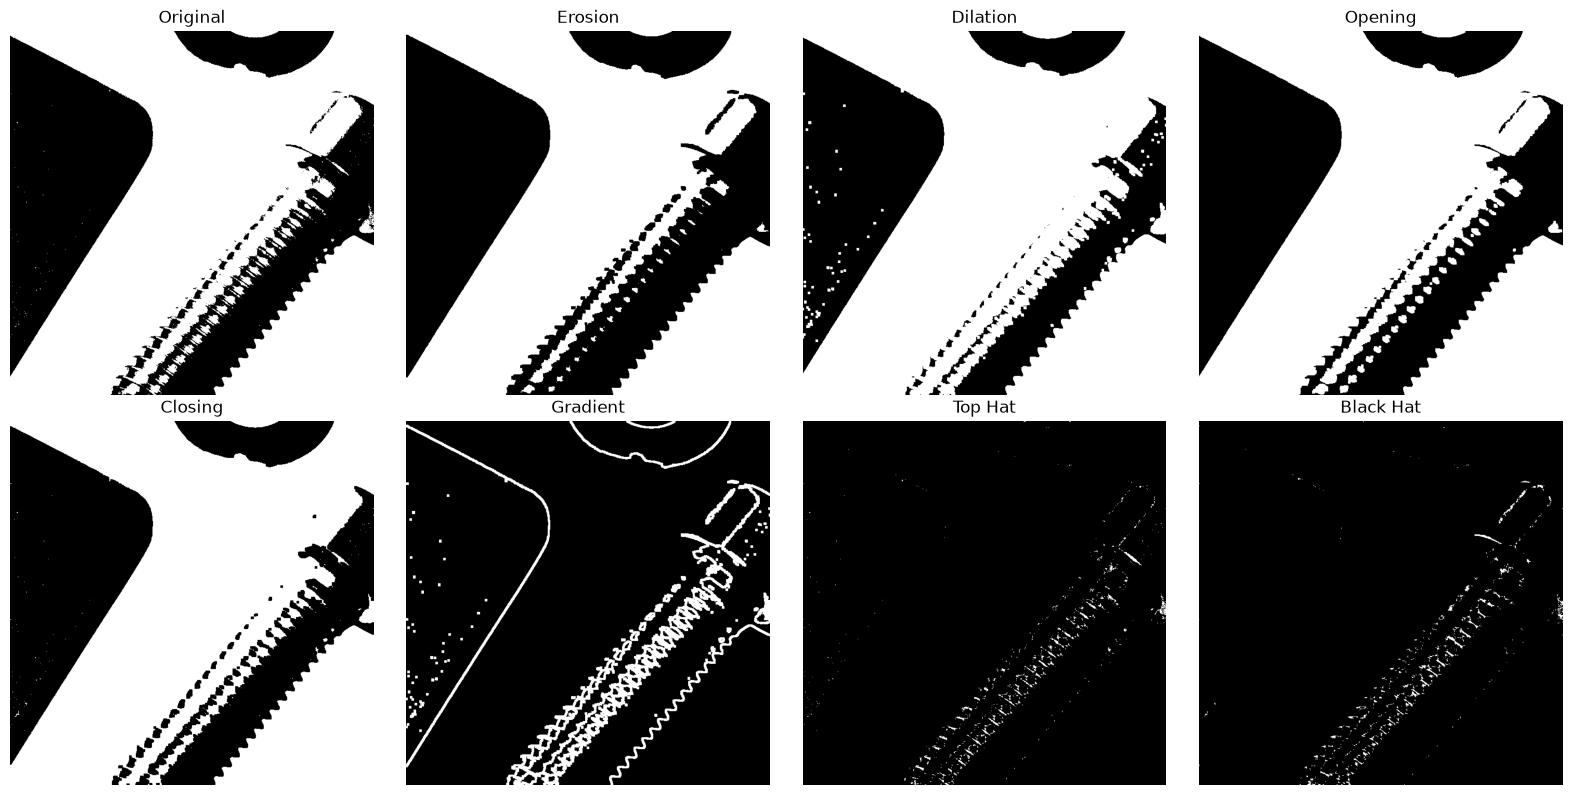

In [20]:
# --- Generate a synthetic binary image to work with ---
img = otsu[300:1000,800:1500]
 
kernel = np.ones((5, 5), np.uint8)
 
# --- Basic operations ---
erosion = cv2.erode(img, kernel, iterations=1)
dilation = cv2.dilate(img, kernel, iterations=1)
 
# --- Compound operations (via morphologyEx) ---
opening = cv2.morphologyEx(img, cv2.MORPH_OPEN, kernel)     # erosion then dilation
closing = cv2.morphologyEx(img, cv2.MORPH_CLOSE, kernel)    # dilation then erosion
gradient = cv2.morphologyEx(img, cv2.MORPH_GRADIENT, kernel)  # dilation - erosion
tophat = cv2.morphologyEx(img, cv2.MORPH_TOPHAT, kernel)    # original - opening
blackhat = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, kernel)  # closing - original
 
results = [
    ('Original', img),
    ('Erosion', erosion),
    ('Dilation', dilation),
    ('Opening', opening),
    ('Closing', closing),
    ('Gradient', gradient),
    ('Top Hat', tophat),
    ('Black Hat', blackhat),
]
 
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.ravel()
 
for ax, (title, im) in zip(axes, results):
    ax.imshow(im, cmap='gray', vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis('off')
 
plt.tight_layout()
plt.show()